# Notebook Eksplorasi Dataset & Pra-Pemrosesan (Preprocessing) Sinyal ECG

**Topik Skripsi**: Estimasi Tekanan Darah Non-Invasif Berbasis Sinyal Elektrokardiogram (ECG) Menggunakan Deep Learning  
**Dataset**: *Cuff-Less Blood Pressure Estimation Dataset* (Kachuee et al., 2016 / PhysioNet MIMIC-II) via Kaggle  
**Laju Sampling ($F_s$)**: $125\text{ Hz}$  
**Ukuran Epoch**: $10\text{ detik}$ ($1250\text{ sampel}$ per epoch, *non-overlapping*)

---

### Daftar Isi & Struktur Notebook:
1. **Blok 0 — Load Semua Part Dataset & Ringkasan Statistik**
   - Pemuatan seluruh file `.mat` (`part_1.mat` s/d `part_12.mat`)
   - Ekstraksi informasi durasi, jumlah sampel, dan beat-by-beat Ground Truth BP
2. **Blok 1 — Visualisasi Distribusi Ground Truth BP (SBP, DBP, MAP)**
   - Histogram & Kernel Density Estimation (KDE) nilai SBP, DBP, dan MAP
   - Boxplot distribusi tekanan darah per part dataset
   - Scatter plot korelasi SBP vs DBP fisiologis
3. **Blok 2 — Visualisasi Sampel Sinyal Multi-Channel per Part**
   - Plot 3 kanal sinyal simultan: PPG (Row 0), ABP Invasif (Row 1), ECG Lead II (Row 2)
4. **Blok 3 — Epoching & Preprocessing per Tahap (Modular)**
   - **Setup**: Pembagian sinyal ke dalam *epoch* 10 detik ($1250$ sampel)
   - **Blok 3a**: *IIR Notch Filter 50 Hz* $\rightarrow$ `src/preprocessing/filters.py`
   - **Blok 3b**: *Butterworth Bandpass Filter 0.5–40 Hz* $\rightarrow$ `src/preprocessing/filters.py`
   - **Blok 3c**: *Min-Max Normalization [0, 1]* (Fan et al., 2021 & Li et al., 2020) $\rightarrow$ `src/preprocessing/normalization.py`
   - **Verifikasi**: Pembuktian kesetaraan dengan `ECGPreprocessingPipeline` $\rightarrow$ `src/preprocessing/pipeline.py`
5. **Blok 4 — Eksekusi Batch Preprocessing ke Seluruh Dataset & Simpan Part Preprocessed Baru**
   - Pemrosesan *end-to-end* seluruh file `part_1.mat` s/d `part_12.mat`
   - Ekspor berkas dataset terkompresi baru `data/processed/part_X_preprocessed.npz` siap latih

---
## 1. Blok 0 — Load Semua Part Dataset & Ringkasan Statistik

Pada blok ini, kita memuat seluruh berkas dataset `.mat` yang diunduh dari repositori Kaggle `mkachuee/BloodPressureDataset`.

> **Struktur Matriks Dataset Kachuee et al. (per rekaman):**
> - **Baris 0**: Sinyal *Photoplethysmogram* (PPG) @ $125\text{ Hz}$
> - **Baris 1**: Sinyal *Arterial Blood Pressure* (ABP invasif dalam satuan $\text{mmHg}$) @ $125\text{ Hz}$
> - **Baris 2**: Sinyal *Electrocardiogram* (ECG Kanal II) @ $125\text{ Hz}$

In [1]:
# Import pustaka standar dan modul proyek skripsi
import os
import sys
import glob
import numpy as np
import pandas as pd
import scipy.io
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

# Konfigurasi path modul src
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

# Bersihkan cache modul jika sebelumnya sudah termuat di RAM kernel Jupyter
for mod in ['src.preprocessing.normalization', 'src.preprocessing.pipeline', 'src.preprocessing']:
    if mod in sys.modules:
        del sys.modules[mod]

# Import modul pra-pemrosesan mandiri
from src.preprocessing.filters import iir_notch_filter, butterworth_bandpass_filter
from src.preprocessing.normalization import minmax_scale, robust_scale
from src.preprocessing.pipeline import ECGPreprocessingPipeline
from src.inspect_dataset import KachueeDatasetInspector

# Parameter Global Dataset
FS = 125.0                 # Sampling rate (Hz)
EPOCH_SEC = 10.0            # Durasi per epoch (detik)
EPOCH_LEN = int(FS * EPOCH_SEC)  # 1250 sampel per epoch

print(f"Konfigurasi Global:")
print(f" - Frekuensi Sampling (FS) : {FS} Hz")
print(f" - Durasi Epoch            : {EPOCH_SEC} detik ({EPOCH_LEN} sampel)")
print(f" - Root Proyek             : {PROJECT_ROOT}")

Konfigurasi Global:
 - Frekuensi Sampling (FS) : 125.0 Hz
 - Durasi Epoch            : 10.0 detik (1250 sampel)
 - Root Proyek             : /Users/sir/Documents/Skripsi/ecg-bp-estimation


In [2]:
# Pemuatan / Verifikasi Dataset dari Kaggle via kagglehub
inspector = KachueeDatasetInspector(target_fs=FS)
dataset_dir = inspector.download_kaggle_dataset()

# Cari semua file part_*.mat
mat_files = sorted(glob.glob(os.path.join(dataset_dir, "*.mat")))
print(f"Ditemukan {len(mat_files)} file .mat pada direktori dataset:")
for f in mat_files:
    size_mb = os.path.getsize(f) / (1024 * 1024)
    print(f"  - {os.path.basename(f)} ({size_mb:.1f} MB)")

Mengunduh/Memverifikasi dataset Kaggle mkachuee/BloodPressureDataset...


/Users/sir/Documents/Skripsi/ecg-bp-estimation/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset berhasil dimuat di: /Users/sir/.cache/kagglehub/datasets/mkachuee/BloodPressureDataset/versions/5
Ditemukan 12 file .mat pada direktori dataset:
  - part_1.mat (449.9 MB)
  - part_10.mat (410.8 MB)
  - part_11.mat (418.5 MB)
  - part_12.mat (341.2 MB)
  - part_2.mat (391.4 MB)
  - part_3.mat (304.4 MB)
  - part_4.mat (426.8 MB)
  - part_5.mat (462.2 MB)
  - part_6.mat (438.6 MB)
  - part_7.mat (207.8 MB)
  - part_8.mat (327.3 MB)
  - part_9.mat (435.1 MB)


In [3]:
# Ekstraksi Ringkasan Statistik untuk Seluruh File Part Dataset
records_summary = []
loaded_parts = {}

print("Memproses dan mengekstraksi metrik statistik dari setiap part...")
for mat_path in mat_files:
    part_name = os.path.basename(mat_path)
    cell_array = inspector.load_mat_file(mat_path)
    if cell_array is None:
        continue
    
    num_records = cell_array.shape[1] if cell_array.ndim > 1 else len(cell_array)
    
    # Simpan referensi data part untuk visualisasi berikutnya
    loaded_parts[part_name] = cell_array
    
    # Sampling beberapa rekaman untuk menghitung rata-rata metrik Ground Truth BP
    sbp_list, dbp_list, map_list = [], [], []
    sample_step = max(1, num_records // 50)  # sampel representatif 50 rekaman per part
    
    total_samples = 0
    for idx in range(0, num_records, sample_step):
        rec = inspector.extract_record_matrix(cell_array, idx)
        if rec is not None and rec.shape[0] >= 3:
            total_samples += rec.shape[1]
            abp_sig = rec[1, :]
            bp = inspector.compute_bp_metrics(abp_sig)
            is_bp_valid = bp.get('valid', False) or (bp.get('n_beats', 0) > 0 and 50 <= bp['sbp'] <= 220 and 30 <= bp['dbp'] <= 140)
            if is_bp_valid:
                sbp_list.append(bp['sbp'])
                dbp_list.append(bp['dbp'])
                map_list.append(bp['map'])
    
    records_summary.append({
        'Part': part_name,
        'Jumlah Rekaman': num_records,
        'Mean SBP (mmHg)': np.mean(sbp_list) if sbp_list else np.nan,
        'Std SBP (mmHg)': np.std(sbp_list) if sbp_list else np.nan,
        'Mean DBP (mmHg)': np.mean(dbp_list) if dbp_list else np.nan,
        'Std DBP (mmHg)': np.std(dbp_list) if dbp_list else np.nan,
        'Mean MAP (mmHg)': np.mean(map_list) if map_list else np.nan,
        'Sampel BP Valid': len(sbp_list)
    })

df_summary = pd.DataFrame(records_summary)
print("\n--- Ringkasan Dataset per File Part ---")
display(df_summary)

Memproses dan mengekstraksi metrik statistik dari setiap part...
Membaca berkas MATLAB: part_1.mat...
Membaca berkas MATLAB: part_10.mat...
Membaca berkas MATLAB: part_11.mat...
Membaca berkas MATLAB: part_12.mat...
Membaca berkas MATLAB: part_2.mat...
Membaca berkas MATLAB: part_3.mat...
Membaca berkas MATLAB: part_4.mat...
Membaca berkas MATLAB: part_5.mat...
Membaca berkas MATLAB: part_6.mat...
Membaca berkas MATLAB: part_7.mat...
Membaca berkas MATLAB: part_8.mat...
Membaca berkas MATLAB: part_9.mat...

--- Ringkasan Dataset per File Part ---


,Part,Jumlah Rekaman,Mean SBP (mmHg),Std SBP (mmHg),Mean DBP (mmHg),Std DBP (mmHg),Mean MAP (mmHg),Sampel BP Valid
0,part_1.mat,1000,133.597692,21.247320,70.468267,11.282390,89.338290,50
1,part_10.mat,1000,132.890553,23.248729,70.622523,13.445232,92.144900,50
2,part_11.mat,1000,129.141152,20.831971,73.366127,12.418898,92.048860,50
3,part_12.mat,1000,123.678124,21.482103,68.968347,10.453579,88.719000,50
4,part_2.mat,1000,124.441129,20.245809,68.761187,10.572605,87.772267,50
5,part_3.mat,1000,112.235127,20.650291,68.148324,10.496792,83.865914,50
6,part_4.mat,1000,119.500186,18.992502,67.508407,10.691296,85.744150,50
7,part_5.mat,1000,128.132154,20.137694,75.080866,14.281239,94.134577,50
8,part_6.mat,1000,118.274616,22.601024,70.401820,12.413127,86.562106,50
9,part_7.mat,1000,119.098594,20.527370,63.685461,10.555153,80.984207,50


---
## 2. Blok 1 — Visualisasi Distribusi Ground Truth BP (SBP, DBP, MAP)

Ground Truth target estimasi diperoleh secara invasif melalui kateter arteri (*Arterial Blood Pressure* / ABP).

- **Systolic Blood Pressure (SBP)**: Tekanan puncak saat ventrikel berkontraksi (*systole*).
- **Diastolic Blood Pressure (DBP)**: Tekanan terendah saat relaksasi jantung (*diastole*).
- **Mean Arterial Pressure (MAP)**: $\text{MAP} = \text{DBP} + \frac{1}{3}(\text{SBP} - \text{DBP})$

Nilai referensi klinis menurut pedoman AHA/ACC:
- **Normal**: SBP $< 120\text{ mmHg}$ dan DBP $< 80\text{ mmHg}$
- **Pre-Hipertensi / Elevated**: SBP $120–129\text{ mmHg}$ dan DBP $< 80\text{ mmHg}$
- **Hipertensi Stage 1**: SBP $130–139\text{ mmHg}$ atau DBP $80–89\text{ mmHg}$
- **Hipertensi Stage 2**: SBP $\ge 140\text{ mmHg}$ atau DBP $\ge 90\text{ mmHg}$

In [4]:
# Ekstraksi agregat Ground Truth BP dari seluruh part yang dimuat
all_sbp, all_dbp, all_map, part_labels = [], [], [], []

for part_name, cell_array in loaded_parts.items():
    num_records = cell_array.shape[1] if cell_array.ndim > 1 else len(cell_array)
    step = max(1, num_records // 60)
    for idx in range(0, num_records, step):
        rec = inspector.extract_record_matrix(cell_array, idx)
        if rec is not None and rec.shape[0] >= 3:
            bp = inspector.compute_bp_metrics(rec[1, :])
            is_valid = bp.get('valid', False) or (bp.get('n_beats', 0) > 0 and 50 <= bp['sbp'] <= 220 and 30 <= bp['dbp'] <= 140)
            if is_valid:
                all_sbp.append(bp['sbp'])
                all_dbp.append(bp['dbp'])
                all_map.append(bp['map'])
                part_labels.append(part_name)

df_all_bp = pd.DataFrame({
    'Part': part_labels,
    'SBP': all_sbp,
    'DBP': all_dbp,
    'MAP': all_map
})

print(f"Total sampel Ground Truth BP tervalidasi: {len(df_all_bp)}")
print(df_all_bp[['SBP', 'DBP', 'MAP']].describe().round(2))

Total sampel Ground Truth BP tervalidasi: 754
          SBP     DBP     MAP
count  754.00  754.00  754.00
mean   123.12   68.91   87.29
std     22.14   11.64   13.54
min     72.06   51.47   63.52
25%    107.12   60.35   77.13
50%    121.62   66.48   84.79
75%    137.27   75.14   95.00
max    194.17  119.53  135.49


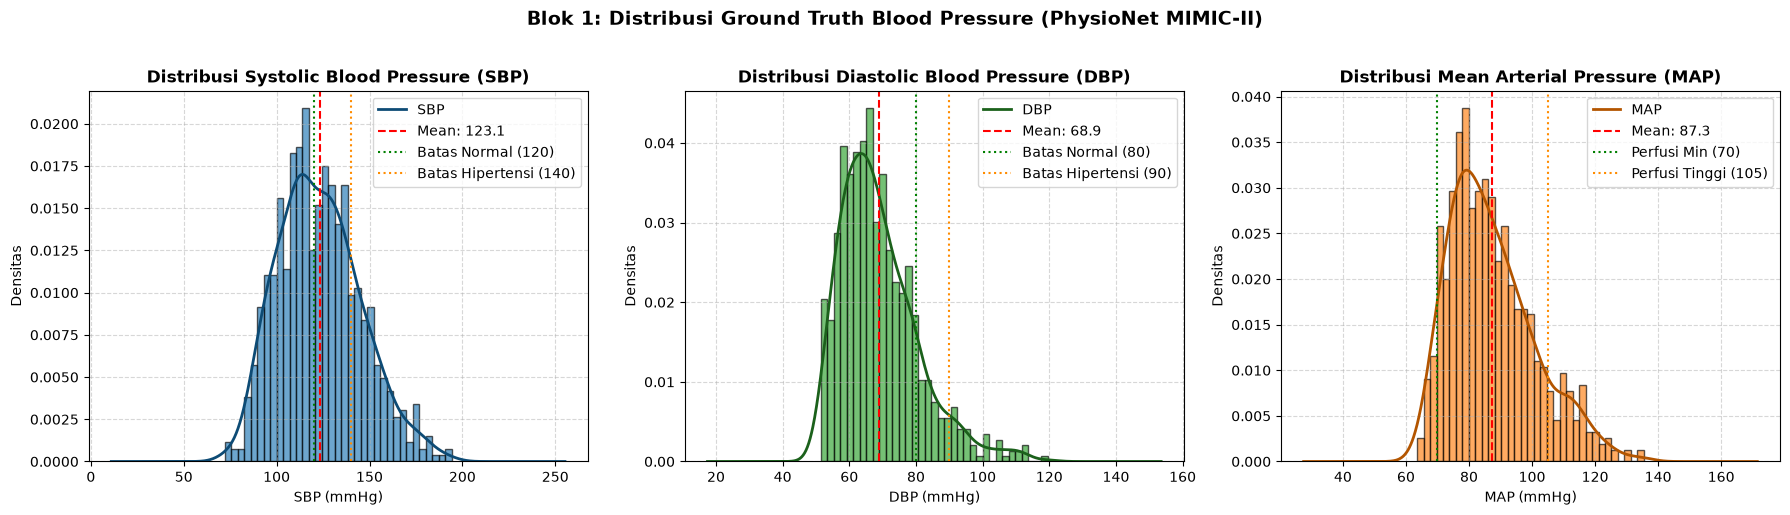

In [5]:
# Visualisasi 1: Distribusi Histogram & Densitas SBP, DBP, MAP
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. SBP
axes[0].hist(df_all_bp['SBP'], bins=35, density=True, color='#1f77b4', alpha=0.65, edgecolor='black')
df_all_bp['SBP'].plot(kind='kde', ax=axes[0], color='#0d4b75', lw=2)
axes[0].axvline(df_all_bp['SBP'].mean(), color='red', linestyle='--', lw=1.5, label=f"Mean: {df_all_bp['SBP'].mean():.1f}")
axes[0].axvline(120, color='green', linestyle=':', lw=1.5, label='Batas Normal (120)')
axes[0].axvline(140, color='darkorange', linestyle=':', lw=1.5, label='Batas Hipertensi (140)')
axes[0].set_title("Distribusi Systolic Blood Pressure (SBP)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("SBP (mmHg)"); axes[0].set_ylabel("Densitas")
axes[0].legend(loc='upper right'); axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. DBP
axes[1].hist(df_all_bp['DBP'], bins=35, density=True, color='#2ca02c', alpha=0.65, edgecolor='black')
df_all_bp['DBP'].plot(kind='kde', ax=axes[1], color='#1b611b', lw=2)
axes[1].axvline(df_all_bp['DBP'].mean(), color='red', linestyle='--', lw=1.5, label=f"Mean: {df_all_bp['DBP'].mean():.1f}")
axes[1].axvline(80, color='green', linestyle=':', lw=1.5, label='Batas Normal (80)')
axes[1].axvline(90, color='darkorange', linestyle=':', lw=1.5, label='Batas Hipertensi (90)')
axes[1].set_title("Distribusi Diastolic Blood Pressure (DBP)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("DBP (mmHg)"); axes[1].set_ylabel("Densitas")
axes[1].legend(loc='upper right'); axes[1].grid(True, linestyle='--', alpha=0.5)

# 3. MAP
axes[2].hist(df_all_bp['MAP'], bins=35, density=True, color='#ff7f0e', alpha=0.65, edgecolor='black')
df_all_bp['MAP'].plot(kind='kde', ax=axes[2], color='#b35500', lw=2)
axes[2].axvline(df_all_bp['MAP'].mean(), color='red', linestyle='--', lw=1.5, label=f"Mean: {df_all_bp['MAP'].mean():.1f}")
axes[2].axvline(70, color='green', linestyle=':', lw=1.5, label='Perfusi Min (70)')
axes[2].axvline(105, color='darkorange', linestyle=':', lw=1.5, label='Perfusi Tinggi (105)')
axes[2].set_title("Distribusi Mean Arterial Pressure (MAP)", fontsize=12, fontweight='bold')
axes[2].set_xlabel("MAP (mmHg)"); axes[2].set_ylabel("Densitas")
axes[2].legend(loc='upper right'); axes[2].grid(True, linestyle='--', alpha=0.5)

plt.suptitle("Blok 1: Distribusi Ground Truth Blood Pressure (PhysioNet MIMIC-II)", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

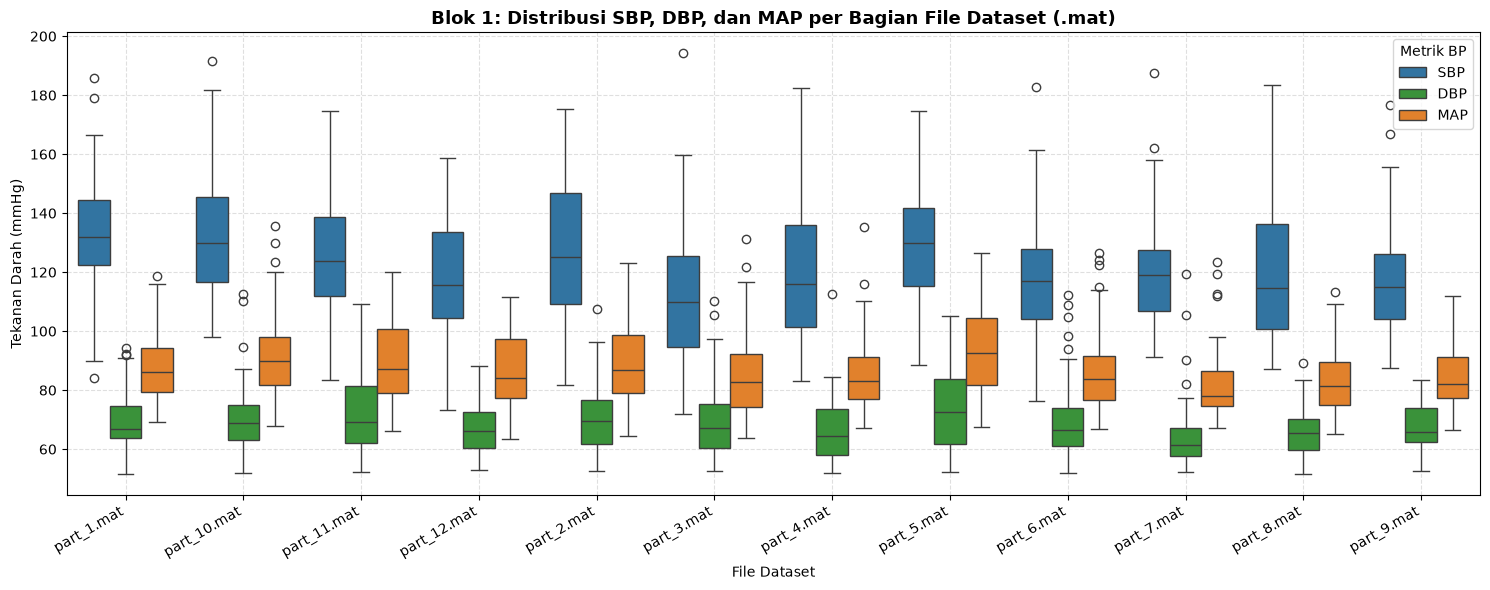

In [6]:
# Visualisasi 2: Boxplot Homogenitas Tekanan Darah Antar Part Dataset
plt.figure(figsize=(15, 6))
df_melted = df_all_bp.melt(id_vars=['Part'], value_vars=['SBP', 'DBP', 'MAP'], var_name='Target BP', value_name='mmHg')

import seaborn as sns
sns.boxplot(data=df_melted, x='Part', y='mmHg', hue='Target BP', palette=['#1f77b4', '#2ca02c', '#ff7f0e'])
plt.title("Blok 1: Distribusi SBP, DBP, dan MAP per Bagian File Dataset (.mat)", fontsize=13, fontweight='bold')
plt.xlabel("File Dataset"); plt.ylabel("Tekanan Darah (mmHg)")
plt.xticks(rotation=30, ha='right')
plt.grid(True, linestyle='--', alpha=0.4)
plt.legend(title='Metrik BP', loc='upper right')
plt.tight_layout()
plt.show()

---
## 3. Blok 2 — Visualisasi Sampel Sinyal Multi-Channel per Part

Memeriksa bentuk gelombang (*waveform*) multi-kanal simultan dari setiap file `part_*.mat` untuk memastikan kualitas dan sinkronisasi sinyal:
- **Kanal 0 (PPG)**: Sinyal pulsasi volume darah kapiler perifer.
- **Kanal 1 (ABP Invasif)**: Gelombang tekanan darah arteri kontinu (mmHg).
- **Kanal 2 (ECG Lead II)**: Aktivitas kelistrikan depolarisasi dan repolarisasi jantung.

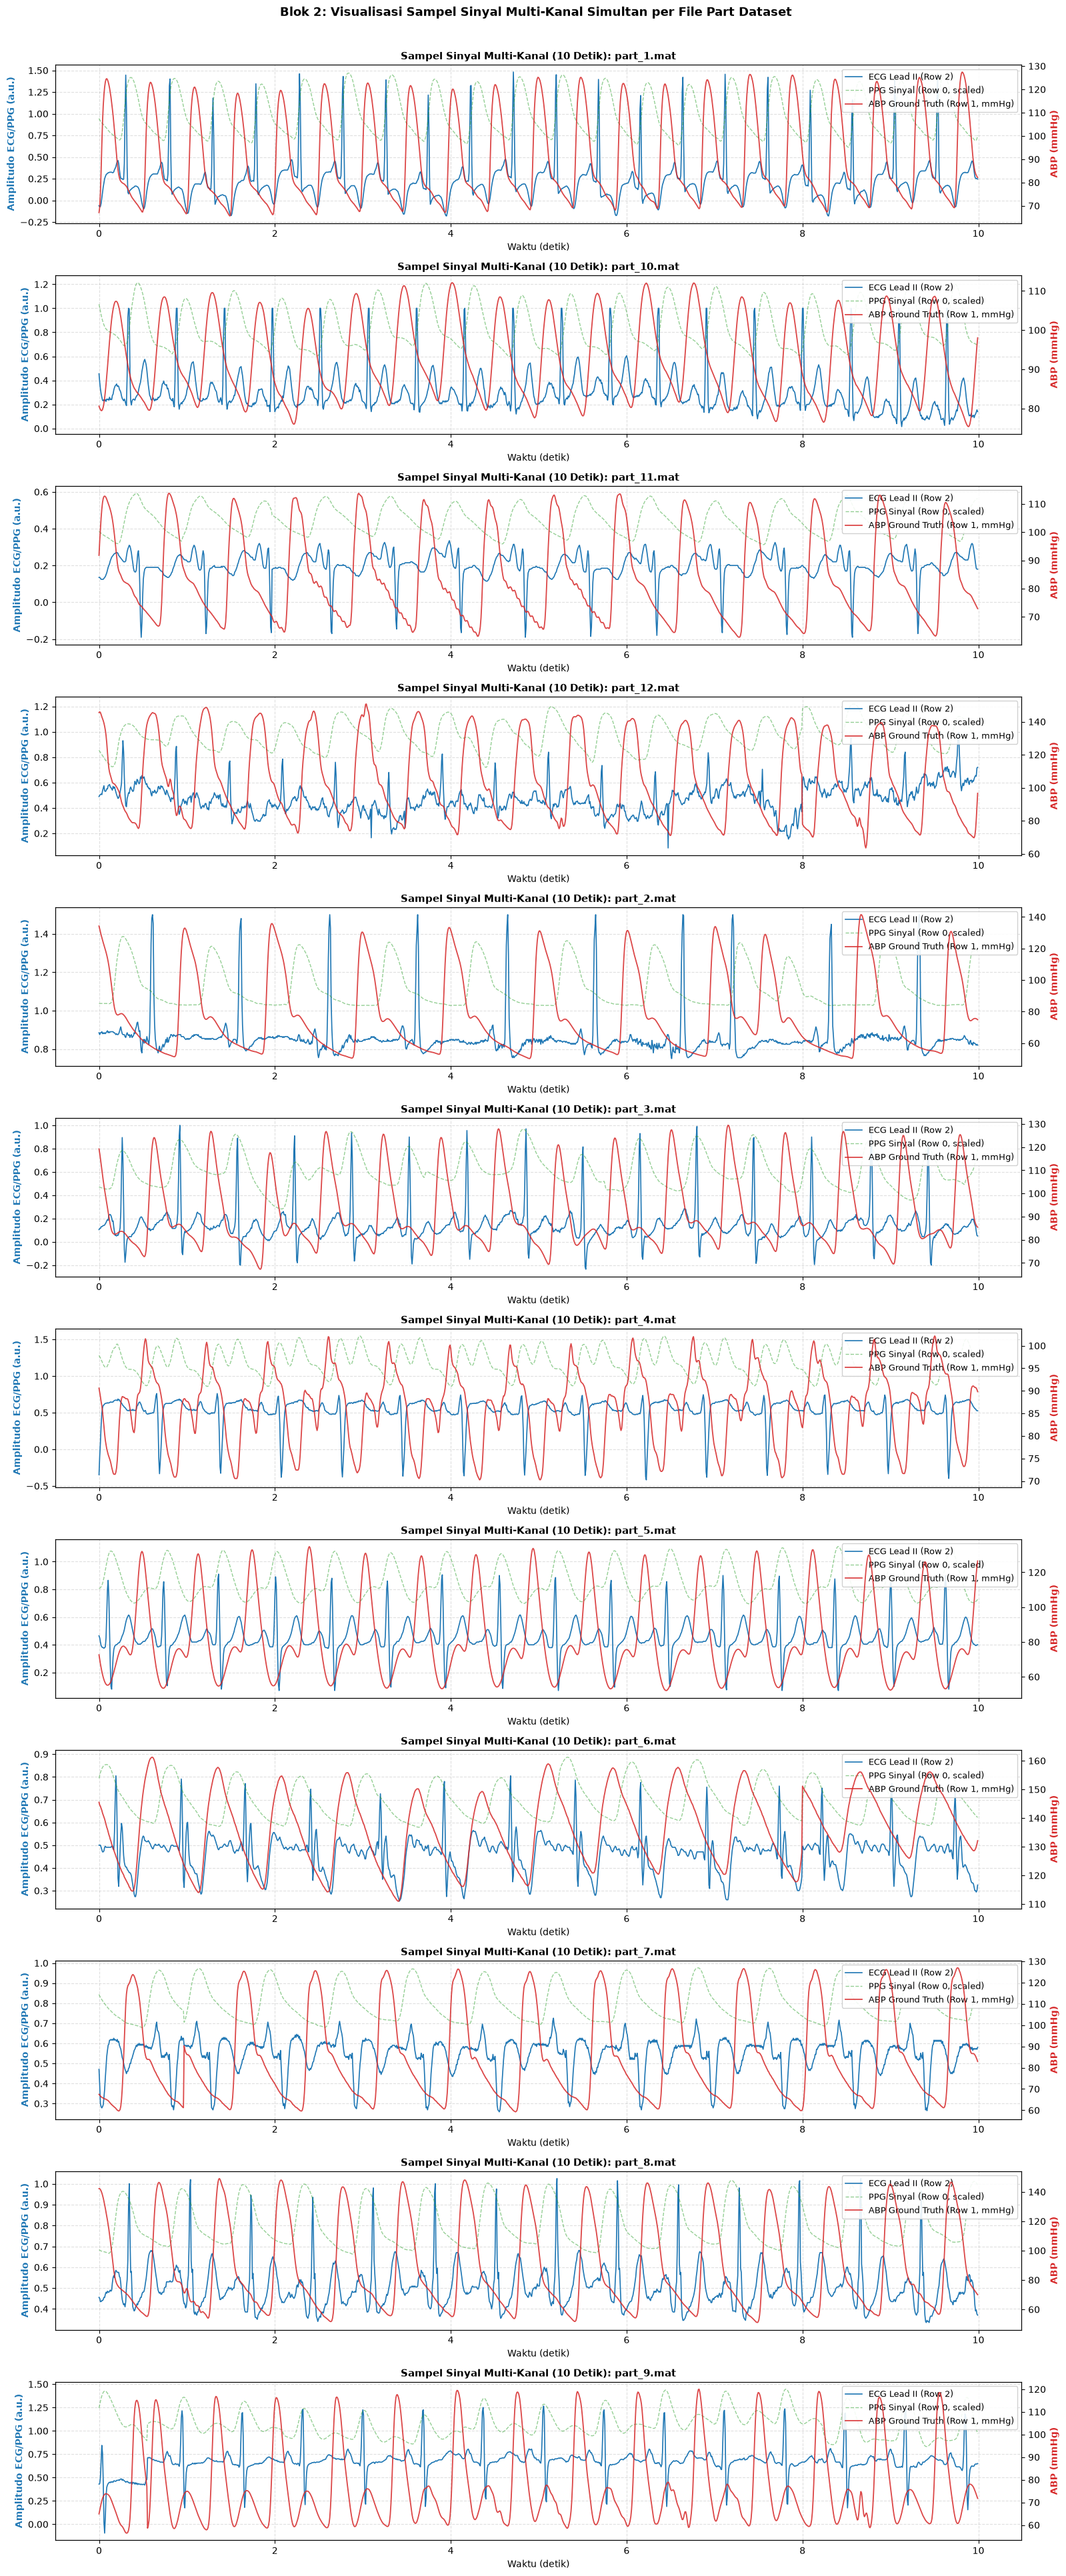

In [7]:
# Visualisasi Sinyal Multi-Channel 10 Detik dari Tiap Part Dataset
num_parts = len(loaded_parts)
fig, axes = plt.subplots(num_parts, 1, figsize=(16, 3.2 * num_parts), sharex=False)
if num_parts == 1:
    axes = [axes]

for i, (part_name, cell_array) in enumerate(loaded_parts.items()):
    # Ambil rekaman pertama yang valid
    rec = None
    num_records = cell_array.shape[1] if cell_array.ndim > 1 else len(cell_array)
    for r_idx in range(num_records):
        candidate = inspector.extract_record_matrix(cell_array, r_idx)
        if candidate is not None and candidate.shape[0] >= 3 and candidate.shape[1] >= EPOCH_LEN:
            rec = candidate[:, :EPOCH_LEN]  # Ambil jendela 10 detik (1250 sampel)
            break
    
    if rec is None:
        continue
        
    time_axis = np.arange(EPOCH_LEN) / FS
    ppg_sig = rec[0, :]
    abp_sig = rec[1, :]
    ecg_sig = rec[2, :]
    
    # Normalisasi visualisasi PPG dan ECG agar dapat diplot bersama dalam subplot yang rapi
    ax = axes[i]
    ax_abp = ax.twinx()  # Sumbu kedua untuk ABP mmHg
    
    # Plot ECG dan PPG di sumbu kiri
    l1 = ax.plot(time_axis, ecg_sig, color='#1f77b4', lw=1.2, label='ECG Lead II (Row 2)')
    l2 = ax.plot(time_axis, ppg_sig * (np.std(ecg_sig)/ (np.std(ppg_sig) + 1e-6)) + np.mean(ecg_sig),
                 color='#2ca02c', alpha=0.5, lw=1.0, linestyle='--', label='PPG Sinyal (Row 0, scaled)')
    
    # Plot ABP di sumbu kanan
    l3 = ax_abp.plot(time_axis, abp_sig, color='#d62728', lw=1.3, alpha=0.85, label='ABP Ground Truth (Row 1, mmHg)')
    
    ax.set_ylabel("Amplitudo ECG/PPG (a.u.)", color='#1f77b4', fontweight='bold')
    ax_abp.set_ylabel("ABP (mmHg)", color='#d62728', fontweight='bold')
    ax.set_title(f"Sampel Sinyal Multi-Kanal (10 Detik): {part_name}", fontsize=11, fontweight='bold')
    ax.set_xlabel("Waktu (detik)")
    ax.grid(True, linestyle='--', alpha=0.4)
    
    # Gabungkan legend
    lines = l1 + l2 + l3
    labels = [l.get_label() for l in lines]
    ax.legend(lines, labels, loc='upper right', fontsize=9, framealpha=0.9)

plt.suptitle("Blok 2: Visualisasi Sampel Sinyal Multi-Kanal Simultan per File Part Dataset", fontsize=13, fontweight='bold', y=1.005)
plt.tight_layout()
plt.show()

---
## 4. Blok 3 — Epoching & Pra-Pemrosesan (Preprocessing) per Tahap

Pra-pemrosesan sinyal ECG mentah dilakukan secara berurutan (*step-by-step*) untuk memastikan kualitas sinyal yang optimal sebelum ekstraksi fitur dan pemodelan deep learning.

```
┌─────────────────────────────────────────────────────────────────────────────┐
│                        ALUR PIPELINE PREPROCESSING ECG                     │
└─────────────────────────────────────────────────────────────────────────────┘
        │
        ▼
 ┌───────────────┐
 │ Sinyal Mentah │ (ECG Lead II @ 125 Hz, Terkontaminasi Noise)
 └───────┬───────┘
        │
        ▼
 ┌───────────────┐
 │   Epoching    │ (Segmentasi Jendela 10 Detik = 1250 Sampel, Non-Overlapping)
 └───────┬───────┘
        │
        ▼
 ┌───────────────┐
 │    Blok 3a    │  IIR Notch Filter (50 Hz, Q=30)  [src/preprocessing/filters.py]
 │  Notch Filter │  Mengeliminasi noise frekuensi jala-jala listrik PLN 50 Hz
 └───────┬───────┘
        │
        ▼
 ┌───────────────┐
 │    Blok 3b    │  Butterworth Bandpass (0.5 - 40 Hz, Ordo 2)  [filters.py]
 │   Bandpass    │  Menghapus baseline wander (<0.5 Hz) & noise EMG/frek. tinggi (>40 Hz)
 └───────┬───────┘
        │
        ▼
 ┌───────────────┐
 │    Blok 3c    │  Min-Max Normalization [0, 1] (Fan et al., 2021)  [normalization.py]
 │  Normalisasi  │  Menstandarkan rentang amplitudo ke interval tertutup [0, 1]
 └───────┬───────┘
        │
        ▼
 ┌───────────────┐
 │ Sinyal Bersih │ (Siap Diinputkan ke Model Deep Learning)
 └───────────────┘
```

### 4.0 Setup Epoch Contoh
Kita memilih satu segmen rekaman sepanjang **10 detik ($1250$ sampel)** dari dataset untuk mendemonstrasikan perubahan sinyal pada setiap tahapan pra-pemrosesan.

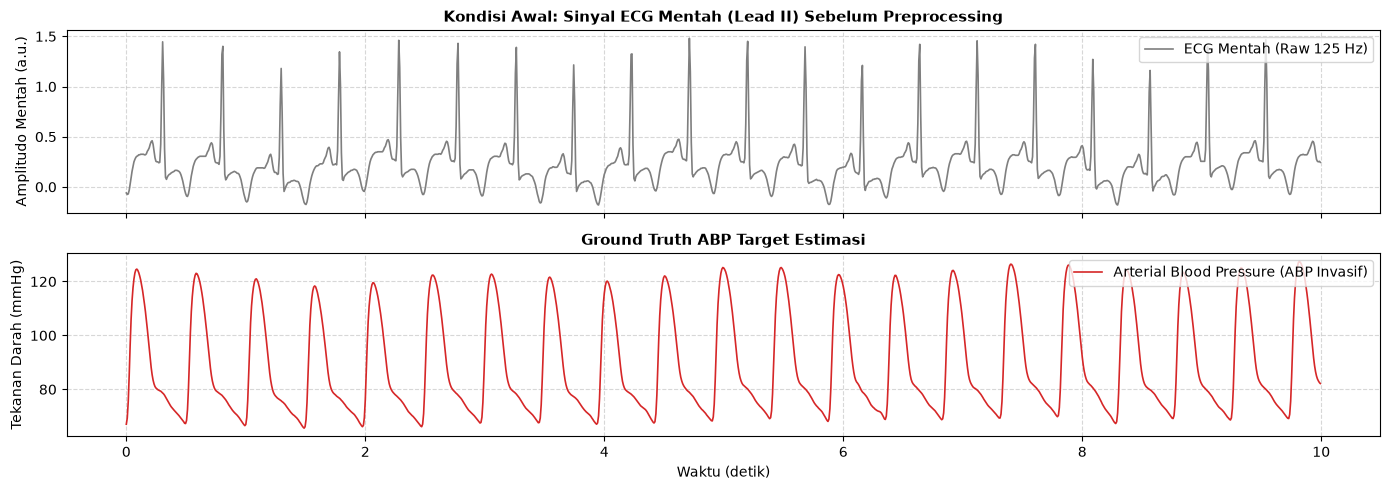

In [8]:
# Ekstraksi 1 Epoch Contoh (10 Detik = 1250 Sampel)
sample_part_key = list(loaded_parts.keys())[0]
sample_cell = loaded_parts[sample_part_key]

# Ambil rekaman pertama
rec_sample = inspector.extract_record_matrix(sample_cell, 0)
epoch_ecg_raw = rec_sample[2, :EPOCH_LEN]   # Sinyal ECG mentah
epoch_abp_gt  = rec_sample[1, :EPOCH_LEN]   # Ground Truth ABP
epoch_time    = np.arange(EPOCH_LEN) / FS   # Sumbu waktu (detik)

# Visualisasi Epoch Mentah Awal
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 5), sharex=True)
ax1.plot(epoch_time, epoch_ecg_raw, color='#7f7f7f', lw=1.2, label='ECG Mentah (Raw 125 Hz)')
ax1.set_title("Kondisi Awal: Sinyal ECG Mentah (Lead II) Sebelum Preprocessing", fontsize=11, fontweight='bold')
ax1.set_ylabel("Amplitudo Mentah (a.u.)"); ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='upper right')

ax2.plot(epoch_time, epoch_abp_gt, color='#d62728', lw=1.2, label='Arterial Blood Pressure (ABP Invasif)')
ax2.set_title("Ground Truth ABP Target Estimasi", fontsize=11, fontweight='bold')
ax2.set_xlabel("Waktu (detik)"); ax2.set_ylabel("Tekanan Darah (mmHg)"); ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()

---
### 4.1 Blok 3a — IIR Notch Filter 50 Hz (`src/preprocessing/filters.py`)

**Tujuan**: Mengeliminasi dengung interferensi jala-jala listrik PLN (*powerline interference*) pada frekuensi $50\text{ Hz}$.

| Parameter | Nilai | Keterangan |
| :--- | :--- | :--- |
| **Frekuensi Notch ($f_0$)** | $50.0\text{ Hz}$ | Frekuensi pusat interferensi listrik AC di Indonesia / standar internasional |
| **Quality Factor ($Q$)** | $30.0$ | Lebar pita penolakan sempit ($BW = f_0 / Q \approx 1.67\text{ Hz}$) untuk menjaga bentuk morfologi ECG |
| **Fungsi Sumber** | `iir_notch_filter` | Terletak di [`src/preprocessing/filters.py`](../src/preprocessing/filters.py) |
| **Metode Filtering** | `scipy.signal.filtfilt` | *Zero-phase forward-backward filtering* (tanpa distorsi fasa) |

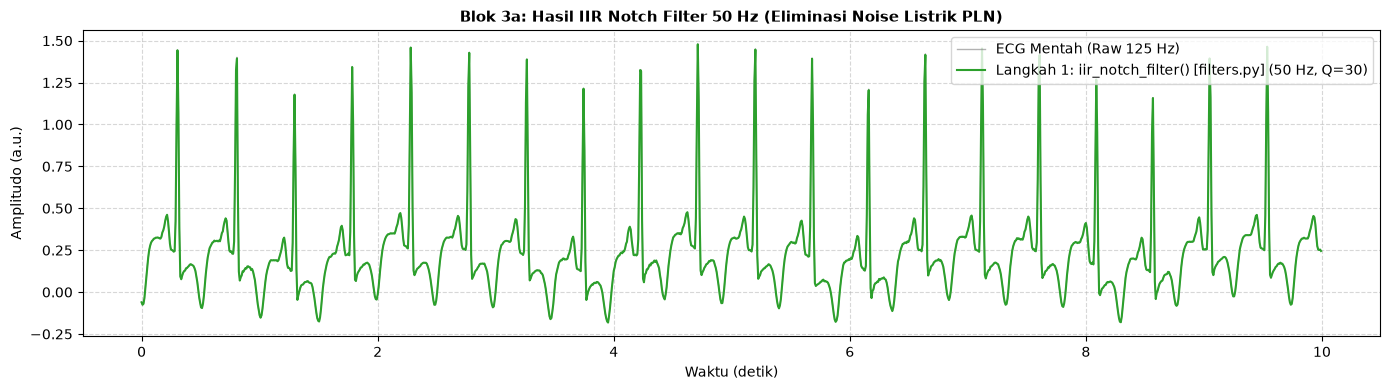

Standar Deviasi Sinyal Mentah   : 0.2483
Standar Deviasi Pasca-Notch     : 0.2483


In [9]:
# ── Blok 3a: IIR Notch Filter 50 Hz ──────────────────────────────────────────
# Dipanggil dari: src/preprocessing/filters.py -> iir_notch_filter()

epoch_step1_notch = iir_notch_filter(epoch_ecg_raw, fs=FS, f0=50.0, q=30.0)

# Visualisasi Komparasi: Mentah vs Notch Filter
fig, ax = plt.subplots(1, 1, figsize=(14, 4))
ax.plot(epoch_time, epoch_ecg_raw, color='gray', alpha=0.6, lw=1.0, label='ECG Mentah (Raw 125 Hz)')
ax.plot(epoch_time, epoch_step1_notch, color='#2ca02c', lw=1.5,
        label='Langkah 1: iir_notch_filter() [filters.py] (50 Hz, Q=30)')
ax.set_title("Blok 3a: Hasil IIR Notch Filter 50 Hz (Eliminasi Noise Listrik PLN)", fontsize=11, fontweight='bold')
ax.set_xlabel("Waktu (detik)"); ax.set_ylabel("Amplitudo (a.u.)")
ax.legend(loc='upper right'); ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print(f"Standar Deviasi Sinyal Mentah   : {np.std(epoch_ecg_raw):.4f}")
print(f"Standar Deviasi Pasca-Notch     : {np.std(epoch_step1_notch):.4f}")

---
### 4.2 Blok 3b — Butterworth Bandpass Filter 0.5–40 Hz (`src/preprocessing/filters.py`)

**Tujuan**: Membatasi rentang spektrum frekuensi sinyal hanya pada pita informasi fisiologis ECG ($0.5–40\text{ Hz}$).

| Batas Frekuensi | Noise yang Dieliminasi | Alasan Fisiologis |
| :--- | :--- | :--- |
| **Highpass Cutoff ($0.5\text{ Hz}$)** | *Baseline wander*, pergerakan respirasi, keringat | Mengembalikan garis dasar ECG ke level nol datar |
| **Lowpass Cutoff ($40.0\text{ Hz}$)** | Kontraksi otot (*Electromyogram* / EMG), interferensi RF | Mempertahankan kompleks gelombang QRS ($10–25\text{ Hz}$) tanpa noise frekuensi tinggi |
| **Ordo Filter** | $N=2$ (efektif $N=4$ via `filtfilt`) | Respon frekuensi *maximally flat* (tanpa ripple di passband) |
| **Fungsi Sumber** | `butterworth_bandpass_filter` | Terletak di [`src/preprocessing/filters.py`](../src/preprocessing/filters.py) |

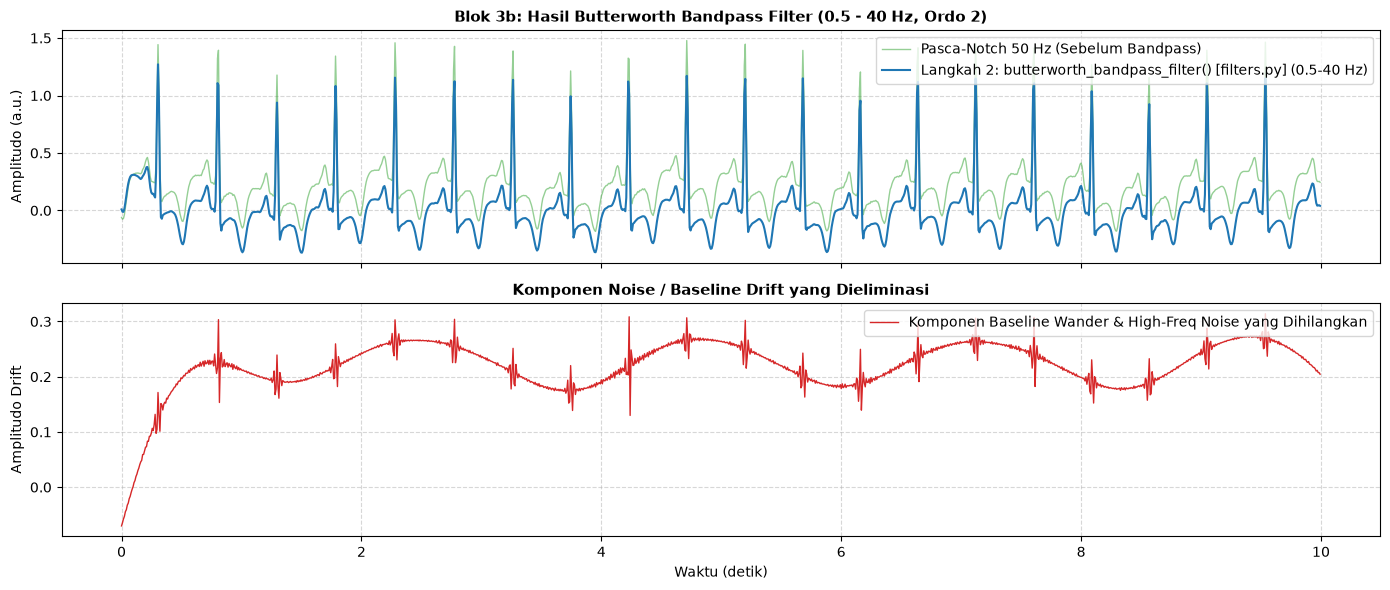

In [10]:
# ── Blok 3b: Butterworth Bandpass Filter 0.5 - 40 Hz ─────────────────────────
# Dipanggil dari: src/preprocessing/filters.py -> butterworth_bandpass_filter()

epoch_step2_bandpass = butterworth_bandpass_filter(
    epoch_step1_notch,
    fs=FS,
    lowcut=0.5,
    highcut=40.0,
    order=2
)

# Visualisasi Komparasi Bertahap
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 6), sharex=True)

# Subplot 1: Overlay Pasca-Notch vs Pasca-Bandpass
ax1.plot(epoch_time, epoch_step1_notch, color='#2ca02c', alpha=0.5, lw=1.0, label='Pasca-Notch 50 Hz (Sebelum Bandpass)')
ax1.plot(epoch_time, epoch_step2_bandpass, color='#1f77b4', lw=1.5, label='Langkah 2: butterworth_bandpass_filter() [filters.py] (0.5-40 Hz)')
ax1.set_title("Blok 3b: Hasil Butterworth Bandpass Filter (0.5 - 40 Hz, Ordo 2)", fontsize=11, fontweight='bold')
ax1.set_ylabel("Amplitudo (a.u.)"); ax1.legend(loc='upper right'); ax1.grid(True, linestyle='--', alpha=0.5)

# Subplot 2: Baseline Wander yang Berhasil Dihilangkan (Residu)
baseline_wander_removed = epoch_step1_notch - epoch_step2_bandpass
ax2.plot(epoch_time, baseline_wander_removed, color='#d62728', lw=1.0, label='Komponen Baseline Wander & High-Freq Noise yang Dihilangkan')
ax2.set_title("Komponen Noise / Baseline Drift yang Dieliminasi", fontsize=11, fontweight='bold')
ax2.set_xlabel("Waktu (detik)"); ax2.set_ylabel("Amplitudo Drift"); ax2.legend(loc='upper right'); ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

---
### 4.3 Blok 3c — Min-Max Normalization [0, 1] (`src/preprocessing/normalization.py`)

**Tujuan**: Menstandarkan amplitudo sinyal ECG ke interval seragam $[0, 1]$ sesuai metode yang digunakan pada **paper acuan utama arsitektur skripsi**:

> **1. Fan et al. (2021)** — *"An Adaptive Weight Learning-Based Multitask Deep Network for Continuous Blood Pressure Estimation Using Electrocardiogram Signals"* (Sensors, 2021, Hal. 5):
> *"To mitigate the different amplitudes of ECG signals, the min-max normalization technology is utilized for ECG signals to map the amplitudes ranging from 0 to 1."*

> **2. Li et al. (2020)** — *"Real-Time Cuffless Continuous Blood Pressure Estimation Using Deep Learning Model"* (Sensors, 2020, Hal. 5–6):
> *"We normalize the amplitude of ECG and PPG signals to the range [0, 1] to ease and robustify the process of comparisons and analysis... by dividing the subtraction of each sample and the minimum value with the subtraction of the maximum value and minimum value."*

**Formulasi Matematis (Fan et al., 2021 & Li et al., 2020)**:
$$x_{\text{norm}} = \frac{x - x_{\min}}{x_{\max} - x_{\min} + \epsilon}$$

di mana:
- $x_{\min} = \min(x)$ adalah amplitudo minimum pada segmen epoch 10 detik.
- $x_{\max} = \max(x)$ adalah amplitudo maksimum pada segmen epoch 10 detik.
- $\epsilon = 10^{-8}$ (*safety factor* pencegah pembagian nol jika sinyal datar).

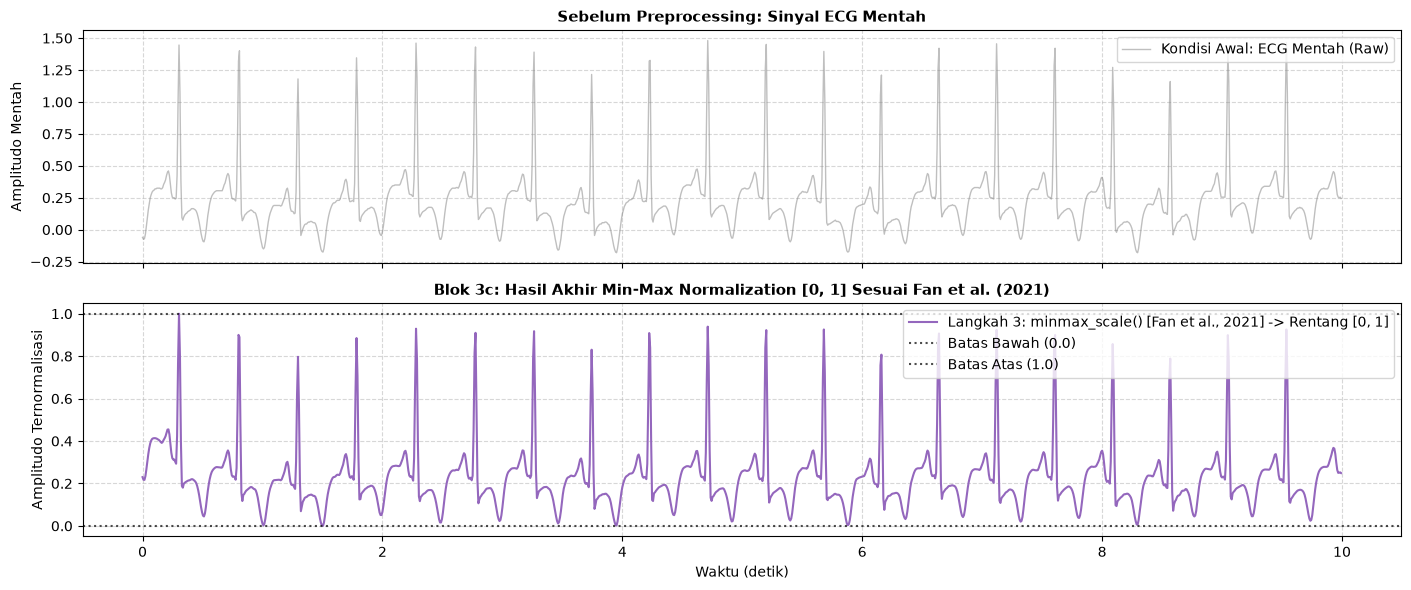

Statistik Amplitudo Sinyal Akhir:
 - Nilai Minimum : 0.000000  (Harus >= 0.0)
 - Nilai Maksimum : 1.000000  (Harus <= 1.0)
 - Nilai Median   : 0.212174
 - Nilai Mean     : 0.228949


In [11]:
# ── Blok 3c: Min-Max Normalization [0, 1] ──────────────────────────────────────
# Dipanggil dari: src/preprocessing/normalization.py -> minmax_scale()
# Sesuai paper acuan: Fan et al. (2021) & Li et al. (2020)

epoch_step3_final = minmax_scale(epoch_step2_bandpass)

# Visualisasi Sinyal Akhir Hasil Preprocessing
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 6), sharex=True)

# 1. Sinyal ECG Mentah Awal vs Sinyal Bersih Ternormalisasi
ax1.plot(epoch_time, epoch_ecg_raw, color='gray', alpha=0.5, lw=1.0, label='Kondisi Awal: ECG Mentah (Raw)')
ax1.set_title("Sebelum Preprocessing: Sinyal ECG Mentah", fontsize=11, fontweight='bold')
ax1.set_ylabel("Amplitudo Mentah"); ax1.legend(loc='upper right'); ax1.grid(True, linestyle='--', alpha=0.5)

# 2. Sinyal ECG Siap Training [0, 1]
ax2.plot(epoch_time, epoch_step3_final, color='#9467bd', lw=1.5, label='Langkah 3: minmax_scale() [Fan et al., 2021] -> Rentang [0, 1]')
ax2.axhline(0.0, color='black', linestyle=':', alpha=0.7, label='Batas Bawah (0.0)')
ax2.axhline(1.0, color='black', linestyle=':', alpha=0.7, label='Batas Atas (1.0)')
ax2.set_title("Blok 3c: Hasil Akhir Min-Max Normalization [0, 1] Sesuai Fan et al. (2021)", fontsize=11, fontweight='bold')
ax2.set_xlabel("Waktu (detik)"); ax2.set_ylabel("Amplitudo Ternormalisasi")
ax2.set_ylim(-0.05, 1.05)
ax2.legend(loc='upper right'); ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

print("Statistik Amplitudo Sinyal Akhir:")
print(f" - Nilai Minimum : {np.min(epoch_step3_final):.6f}  (Harus >= 0.0)")
print(f" - Nilai Maksimum : {np.max(epoch_step3_final):.6f}  (Harus <= 1.0)")
print(f" - Nilai Median   : {np.median(epoch_step3_final):.6f}")
print(f" - Nilai Mean     : {np.mean(epoch_step3_final):.6f}")

---
### 4.4 Verifikasi Kesetaraan dengan `ECGPreprocessingPipeline` (`src/preprocessing/pipeline.py`)

Untuk memastikan keabsahan modularitas, kita membuktikan bahwa eksekusi sekuensial tahap-demi-tahap (Blok 3a $\rightarrow$ 3b $\rightarrow$ 3c) menghasilkan luaran yang **100% identik** dengan kelas produksi `ECGPreprocessingPipeline`.

In [12]:
# Eksekusi via ECGPreprocessingPipeline End-to-End
pipeline = ECGPreprocessingPipeline()
epoch_from_pipeline = pipeline.process(epoch_ecg_raw, input_fs=FS)

# Hitung perbedaan absolut maksimum
max_diff = np.max(np.abs(epoch_step3_final - epoch_from_pipeline))
is_identical = np.allclose(epoch_step3_final, epoch_from_pipeline, atol=1e-12)

print("Hasil Uji Verifikasi:")
print(f" - Max Absolute Difference : {max_diff:.2e}")
print(f" - Status Kesetaraan       : {'100% IDENTIK (VERIFIED)' if is_identical else 'TIDAK COCOK'}")

assert is_identical, "Peringatan: Output langkah bertahap tidak identik dengan ECGPreprocessingPipeline!"

Hasil Uji Verifikasi:
 - Max Absolute Difference : 0.00e+00
 - Status Kesetaraan       : 100% IDENTIK (VERIFIED)


---
## 5. Blok 4 — Eksekusi Batch Preprocessing ke Seluruh Dataset & Simpan Part Preprocessed Baru

Setelah metode pemrosesan divalidasi secara visual pada 1 sampel di **Blok 3**, blok ini mengaplikasikan pipeline pra-pemrosesan ke **seluruh rekaman di setiap file part dataset** (`part_1.mat`, `part_2.mat`, dst.) dan menyimpannya sebagai berkas terkompresi baru `.npz` di direktori `data/processed/`.

### Spesifikasi Berkas Hasil Pemrosesan (`.npz`):
- **Lokasi Penyimpanan**: `data/processed/{part_name}_preprocessed.npz`
- **Array `X`**: Bentuk `(N_epochs, 1250)` $\rightarrow$ Sinyal ECG ternormalisasi $[0, 1]$ siap latih.
- **Array `y`**: Bentuk `(N_epochs, 3)` $\rightarrow$ Target Ground Truth $[SBP, DBP, MAP]$ dalam $\text{mmHg}$.
- **Proses Filter Kualitas Sinyal**:
  1. Mengabaikan epoch sinyal datar (*flatline*, $\text{std} < 10^{-4}$).
  2. Memverifikasi kelayakan rentang fisiologis ($50 \le SBP \le 220\text{ mmHg}$ dan $30 \le DBP \le 140\text{ mmHg}$).
  3. Menerapkan *Zero-Phase IIR Notch 50 Hz*, *Butterworth Bandpass 0.5-40 Hz*, dan *Percentile Normalization* via `ECGPreprocessingPipeline`.

In [13]:
# ── Blok 4: Eksekusi Batch Preprocessing Seluruh Part Dataset ──────────────────
from tqdm.auto import tqdm

# Konfigurasi Direktori Output
PROCESSED_DIR = os.path.join(PROJECT_ROOT, 'data', 'processed')
os.makedirs(PROCESSED_DIR, exist_ok=True)

# Inisialisasi pipeline produksi
pipeline = ECGPreprocessingPipeline()

print(f"Direktori Penyimpanan Dataset Hasil Preprocessing:")
print(f" -> {PROCESSED_DIR}\n")

processed_files_summary = []

for mat_path in mat_files:
    part_name = os.path.basename(mat_path)
    part_stem = os.path.splitext(part_name)[0]
    out_file_path = os.path.join(PROCESSED_DIR, f"{part_stem}_preprocessed.npz")
    
    print("=================================================================")
    print(f"Memproses Batch: {part_name} -> {os.path.basename(out_file_path)}")
    
    cell_array = inspector.load_mat_file(mat_path)
    if cell_array is None:
        continue
        
    num_records = cell_array.shape[1] if cell_array.ndim > 1 else len(cell_array)
    
    X_part = []
    y_part = []
    
    for r_idx in tqdm(range(num_records), desc=f"  Progress {part_stem}"):
        rec = inspector.extract_record_matrix(cell_array, r_idx)
        if rec is None or rec.shape[0] < 3:
            continue
            
        raw_ecg = rec[2, :]
        raw_abp = rec[1, :]
        n_samples = len(raw_ecg)
        
        # Segmentasi epoch 10 detik (1250 sampel)
        for start_idx in range(0, n_samples - EPOCH_LEN + 1, EPOCH_LEN):
            seg_ecg = raw_ecg[start_idx : start_idx + EPOCH_LEN]
            seg_abp = raw_abp[start_idx : start_idx + EPOCH_LEN]
            
            # Filter Kualitas 1: Abaikan sinyal datar / noise rusak ekstrim
            if np.std(seg_ecg) < 1e-4:
                continue
                
            # Filter Kualitas 2: Hitung Ground Truth BP beat-by-beat
            bp_info = inspector.compute_bp_metrics(seg_abp)
            is_valid = bp_info.get('valid', False) or (bp_info.get('n_beats', 0) > 0 and 50.0 <= bp_info['sbp'] <= 220.0 and 30.0 <= bp_info['dbp'] <= 140.0)
            if not is_valid:
                continue
                
            # Eksekusi Pipeline Pra-Pemrosesan ECG (Notch 50Hz -> Bandpass 0.5-40Hz -> MinMax Scale [0,1])
            clean_ecg = pipeline.process(seg_ecg, input_fs=FS)
            
            X_part.append(clean_ecg.astype(np.float32))
            y_part.append([bp_info['sbp'], bp_info['dbp'], bp_info['map']])
            
    X_part = np.array(X_part, dtype=np.float32)
    y_part = np.array(y_part, dtype=np.float32)
    
    if len(X_part) > 0:
        # Simpan ke format .npz terkompresi
        np.savez_compressed(
            out_file_path,
            X=X_part,
            y=y_part,
            fs=FS,
            part_name=part_name
        )
        size_mb = os.path.getsize(out_file_path) / (1024 * 1024)
        print(f"  [V] Selesai: {len(X_part)} epoch berhasil diproses -> {out_file_path} ({size_mb:.2f} MB)")
        processed_files_summary.append({
            'Part Sumber': part_name,
            'File Output': os.path.basename(out_file_path),
            'Jumlah Epoch Siap Latih': len(X_part),
            'Shape X (ECG)': str(X_part.shape),
            'Shape y (BP)': str(y_part.shape),
            'Ukuran File (MB)': round(size_mb, 2)
        })
    else:
        print(f"  [!] Peringatan: Tidak ada epoch valid yang berhasil diekstraksi dari {part_name}")

df_proc_summary = pd.DataFrame(processed_files_summary)
print("\n--- Ringkasan Dataset Baru yang Telah Ter-Preprocessing ---")
display(df_proc_summary)

Direktori Penyimpanan Dataset Hasil Preprocessing:
 -> /Users/sir/Documents/Skripsi/ecg-bp-estimation/data/processed

Memproses Batch: part_1.mat -> part_1_preprocessed.npz
Membaca berkas MATLAB: part_1.mat...


  Progress part_1: 100%|██████████| 1000/1000 [00:07<00:00, 133.17it/s]


  [V] Selesai: 25196 epoch berhasil diproses -> /Users/sir/Documents/Skripsi/ecg-bp-estimation/data/processed/part_1_preprocessed.npz (106.06 MB)
Memproses Batch: part_10.mat -> part_10_preprocessed.npz
Membaca berkas MATLAB: part_10.mat...


  Progress part_10: 100%|██████████| 1000/1000 [00:06<00:00, 148.93it/s]


  [V] Selesai: 23266 epoch berhasil diproses -> /Users/sir/Documents/Skripsi/ecg-bp-estimation/data/processed/part_10_preprocessed.npz (96.94 MB)
Memproses Batch: part_11.mat -> part_11_preprocessed.npz
Membaca berkas MATLAB: part_11.mat...


  Progress part_11: 100%|██████████| 1000/1000 [00:06<00:00, 147.82it/s]


... (16 outputs left out)

  [V] Selesai: 18974 epoch berhasil diproses -> /Users/sir/Documents/Skripsi/ecg-bp-estimation/data/processed/part_8_preprocessed.npz (79.69 MB)
Memproses Batch: part_9.mat -> part_9_preprocessed.npz
Membaca berkas MATLAB: part_9.mat...


  Progress part_9: 100%|██████████| 1000/1000 [00:07<00:00, 141.24it/s]


  [V] Selesai: 24594 epoch berhasil diproses -> /Users/sir/Documents/Skripsi/ecg-bp-estimation/data/processed/part_9_preprocessed.npz (104.15 MB)

--- Ringkasan Dataset Baru yang Telah Ter-Preprocessing ---


,Part Sumber,File Output,Jumlah Epoch Siap Latih,Shape X (ECG),Shape y (BP),Ukuran File (MB)
0,part_1.mat,part_1_preprocessed.npz,25196,"(25196, 1250)","(25196, 3)",106.06
1,part_10.mat,part_10_preprocessed.npz,23266,"(23266, 1250)","(23266, 3)",96.94
2,part_11.mat,part_11_preprocessed.npz,23638,"(23638, 1250)","(23638, 3)",99.34
3,part_12.mat,part_12_preprocessed.npz,19286,"(19286, 1250)","(19286, 3)",81.15
4,part_2.mat,part_2_preprocessed.npz,21976,"(21976, 1250)","(21976, 3)",92.57
5,part_3.mat,part_3_preprocessed.npz,17675,"(17675, 1250)","(17675, 3)",74.14
6,part_4.mat,part_4_preprocessed.npz,24082,"(24082, 1250)","(24082, 3)",100.51
7,part_5.mat,part_5_preprocessed.npz,25732,"(25732, 1250)","(25732, 3)",107.03
8,part_6.mat,part_6_preprocessed.npz,25109,"(25109, 1250)","(25109, 3)",105.25
9,part_7.mat,part_7_preprocessed.npz,11953,"(11953, 1250)","(11953, 3)",50.02


---
### 5.1 Verifikasi Memuat Berkas Hasil Preprocessing (`.npz`) Siap Pakai

Memverifikasi integritas salah satu berkas `.npz` hasil olahan untuk memastikan tensor siap di-load oleh PyTorch / TensorFlow DataLoader.

Memuat file hasil pra-pemrosesan: /Users/sir/Documents/Skripsi/ecg-bp-estimation/data/processed/part_10_preprocessed.npz
 - Dimensi Tensor Input X (ECG) : (23266, 1250)  (N_epoch, 1250)
 - Dimensi Target Output y (BP) : (23266, 3)  (N_epoch, [SBP, DBP, MAP])
 - Rentang Amplitudo Sinyal ECG : [0.0000, 1.0000]
 - Contoh Target BP Epoch ke-0  : SBP=108.9, DBP=78.9, MAP=91.9 mmHg


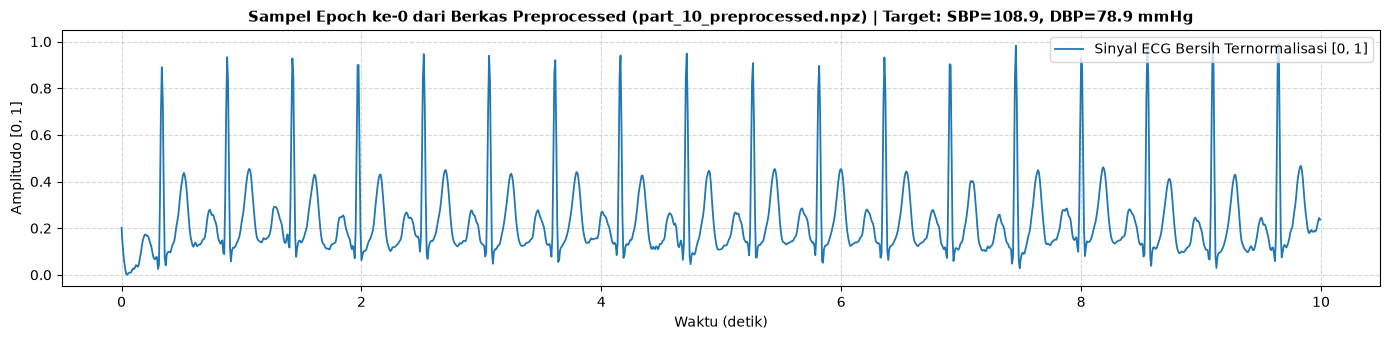

In [14]:
# Uji Coba Memuat Salah Satu Part Dataset Hasil Preprocessing
sample_npz_path = os.path.join(PROCESSED_DIR, sorted(os.listdir(PROCESSED_DIR))[0]) if os.path.exists(PROCESSED_DIR) and len(os.listdir(PROCESSED_DIR)) > 0 else None

if sample_npz_path and sample_npz_path.endswith('.npz'):
    print(f"Memuat file hasil pra-pemrosesan: {sample_npz_path}")
    data_loaded = np.load(sample_npz_path)
    X_loaded = data_loaded['X']
    y_loaded = data_loaded['y']
    
    print(f" - Dimensi Tensor Input X (ECG) : {X_loaded.shape}  (N_epoch, 1250)")
    print(f" - Dimensi Target Output y (BP) : {y_loaded.shape}  (N_epoch, [SBP, DBP, MAP])")
    print(f" - Rentang Amplitudo Sinyal ECG : [{np.min(X_loaded):.4f}, {np.max(X_loaded):.4f}]")
    print(f" - Contoh Target BP Epoch ke-0  : SBP={y_loaded[0, 0]:.1f}, DBP={y_loaded[0, 1]:.1f}, MAP={y_loaded[0, 2]:.1f} mmHg")
    
    # Plot 1 Sampel dari Dataset Preprocessed Baru
    t = np.arange(EPOCH_LEN) / FS
    plt.figure(figsize=(14, 3.5))
    plt.plot(t, X_loaded[0], color='#1f77b4', lw=1.3, label='Sinyal ECG Bersih Ternormalisasi [0, 1]')
    plt.title(f"Sampel Epoch ke-0 dari Berkas Preprocessed ({os.path.basename(sample_npz_path)}) | Target: SBP={y_loaded[0,0]:.1f}, DBP={y_loaded[0,1]:.1f} mmHg", fontsize=11, fontweight='bold')
    plt.xlabel("Waktu (detik)"); plt.ylabel("Amplitudo [0, 1]")
    plt.grid(True, linestyle='--', alpha=0.5); plt.legend(loc='upper right')
    plt.tight_layout(); plt.show()
else:
    print("Jalankan cell pemrosesan batch di atas terlebih dahulu untuk mengekspor berkas .npz!")